In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

### Load Predictions

In [2]:
df_preds = pd.read_csv("../data/predictions/pred_tweets.csv")

### Labelling

In [3]:
# example column names
# text, label, predicted_scores, predicted_label

df_preds = df_preds.copy()

# convert dict-like strings to real dicts if needed
def parse_scores(x):
    if isinstance(x, dict):
        return x
    if isinstance(x, str):
        # handle strings like "{'negative': 0.71, 'positive': 0.18}"
        try:
            return eval(x)
        except:
            return {}
    return {}

df_preds["predicted_scores"] = df_preds["predicted_scores"].apply(parse_scores)

# ensure label order
classes = ["negative", "neutral", "positive"]

# unpack score dictionary into columns
for c in classes:
    df_preds[c] = df_preds["predicted_scores"].apply(lambda d: float(d.get(c, 0.0)))

df_preds["pred_top_score"] = df_preds[classes].max(axis=1)
df_preds["predicted_label"] = df_preds[classes].idxmax(axis=1)

### Confusion Matrix

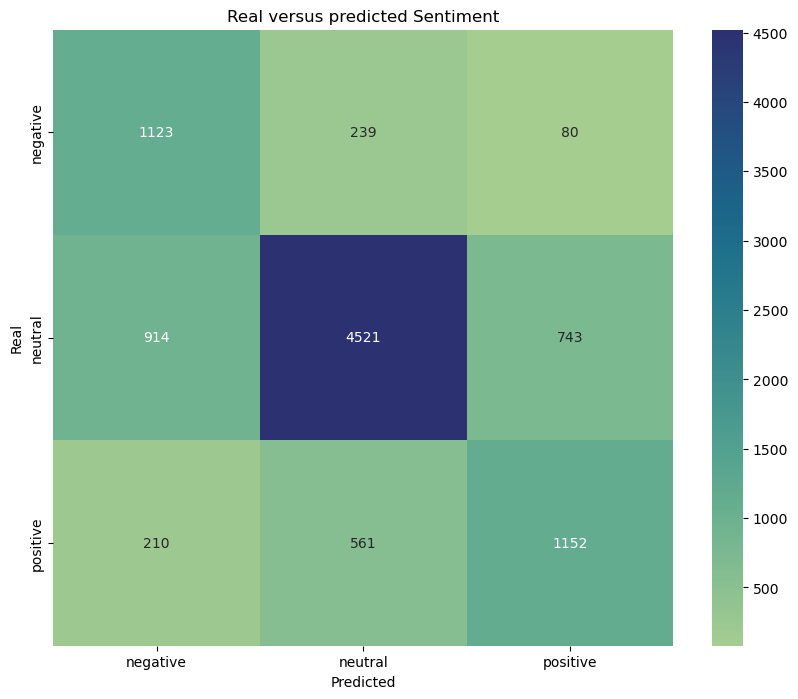

In [4]:
confusion_matrix = pd.crosstab(df_preds["label"], df_preds["predicted_label"]).reindex(index=classes, columns=classes)

plt.figure(figsize=(10,8))
sns.heatmap(confusion_matrix, annot=True, cmap="crest", fmt="d", xticklabels=classes, yticklabels=classes)
plt.title("Real versus predicted Sentiment")
plt.xlabel("Predicted")
plt.ylabel("Real")
plt.show()

### Displaying recall & precision

In [5]:
recall_pos = (1152) / (1152+561+210)
print("Pos", recall_pos)
recall_neg = (1123) / (1123+239+80)
print("Neg", recall_neg)
recall_neut = (4521) / (914+4521+743)
neut_error_rate = 1 - recall_neut
print("Neut", recall_neut)

Pos 0.5990639625585024
Neg 0.7787794729542302
Neut 0.7317902233732599


In [6]:
precision_pos = (1152) / (80+743+1152)
print("Pos", precision_pos)
precision_neg = (1123) / (1123+914+210) 
print("Neg", precision_neg)
precision_neut = (4521) / (4521+239+561) 
print("Neut", precision_neut)

Pos 0.5832911392405064
Neg 0.4997774810858923
Neut 0.8496523209922947


<Figure size 1000x800 with 0 Axes>

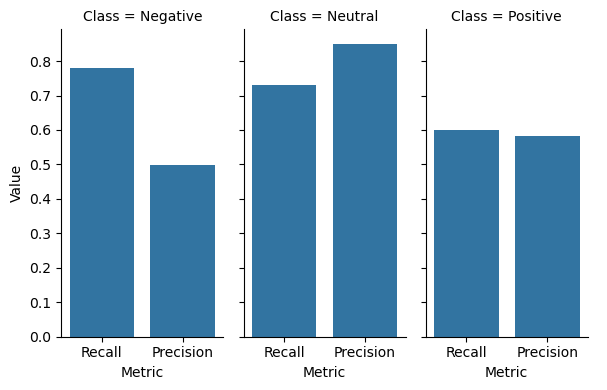

In [7]:
metrics_df = pd.DataFrame({
    "Class": ["Negative","Negative","Neutral","Neutral","Positive","Positive"],
    "Metric": ["Recall", "Precision"]*3,
    "Value": [recall_neg, precision_neg,recall_neut, precision_neut,recall_pos, precision_pos]
})
plt.figure(figsize=(10,8))
sns.catplot(
    metrics_df, kind="bar",
    x="Metric", y="Value", col="Class",
    height=4, aspect=.5,
)
plt.show();

metrics might be important to look at - especially for phase 2. eg. which words drive prediction. and from a more real world aspect, obviously we want to investiate why prec for bullish is so low bcs mistintrepreting a bullish signal can lead to portfolio losses. 

### Scatterplot (relplot)

<Figure size 1000x800 with 0 Axes>

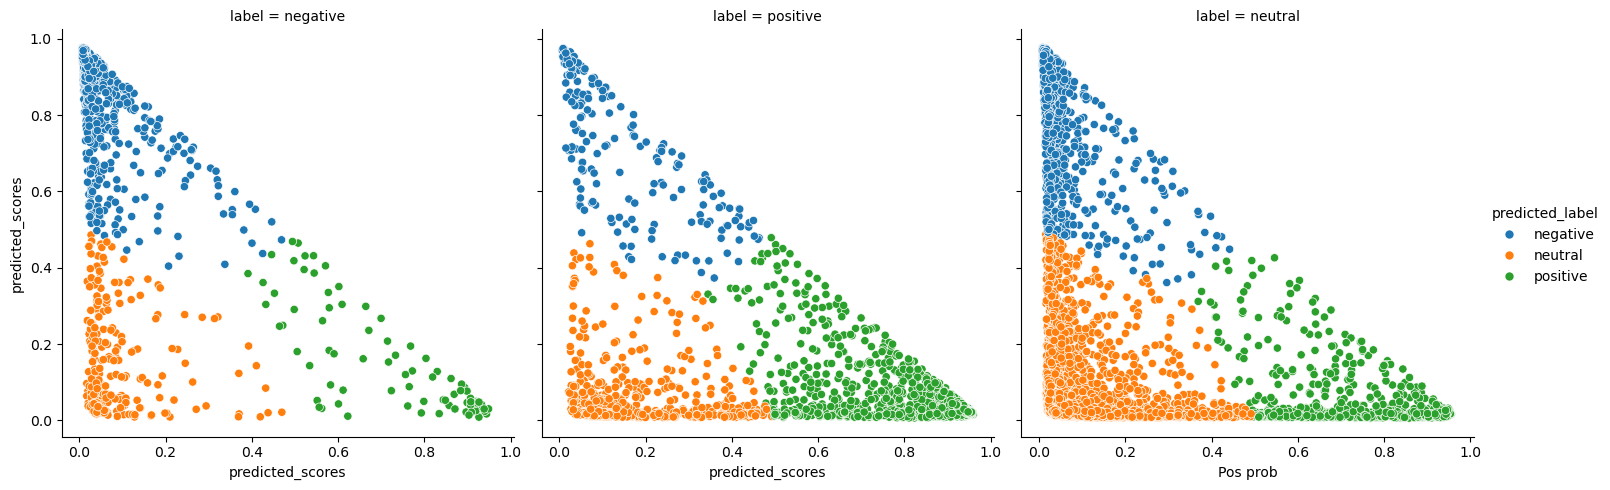

In [8]:
plt.figure(figsize=(10,8))
sns.relplot(
    data = df_preds,
    x= df_preds["predicted_scores"].apply(lambda d: d["positive"]),
    y=df_preds["predicted_scores"].apply(lambda d: d["negative"]),
    col=df_preds["label"],
    hue = df_preds["predicted_label"],
)

plt.xlabel("Pos prob")
plt.ylabel("Neg prob")
plt.show()

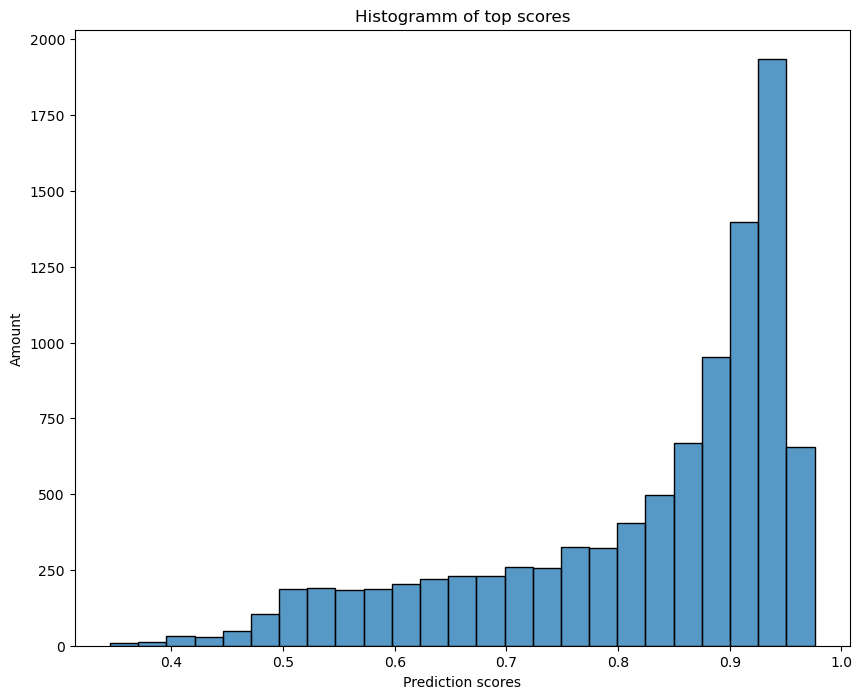

In [9]:
plt.figure(figsize=(10,8))
sns.histplot(
data = df_preds["pred_top_score"], bins=25
)
plt.title("Histogramm of top scores")
plt.xlabel("Prediction scores")
plt.ylabel("Amount")
plt.show()

### These were more general plots

### However to make some more content and spinning a hyptohesis or having a "story" i think it would make sense to have a look at

pred bull but actually bear
pred bear but actually bull

## assume you wanna trade based on sentiment, having your model predict a bullish sentiment for what is actually a bearish tweet (think bigger we let the model analyse financial reports than just tweets) can be lead to unjustified investments and hence losing money

## also the model seems to be quite good at predicting neutral sentiment, so while neutral sentiments are good, bull or bear scenarios have some struggle

## for me basically two questions follow:

### 1. can sentiments predicted better when statements arent reverted (e.g. minimize loss) 

-> here you need to understand the meaning minimze (bad word), loss (also bad word) = positive meaning
or downgrade to buy (technically still positive but sentiment has worsened regardless)

### 2. (red circle) how do tweets expressing negative sentiments that are predicted correctly differ from negative tweets that were predicted incorrectly


In [10]:
df_missclasified = df_preds[
    (df_preds["label"] != df_preds["predicted_label"]) 
    & (df_preds["label"] != "neutral")
    & (df_preds["predicted_label"] != "neutral")
    ].groupby(
        by=["label", "predicted_label"]
    )["pred_top_score"].mean()
df_not_missclasified = df_preds[
    (df_preds["label"] == df_preds["predicted_label"]) 
    & (df_preds["label"] != "neutral")
    & (df_preds["predicted_label"] != "neutral")
    ].groupby(
        by=["label", "predicted_label"]
    )["pred_top_score"].mean()

print(df_missclasified.head())
print("----------------------")
print(df_not_missclasified.head())

label     predicted_label
negative  positive           0.719026
positive  negative           0.730871
Name: pred_top_score, dtype: float64
----------------------
label     predicted_label
negative  negative           0.887454
positive  positive           0.822144
Name: pred_top_score, dtype: float64


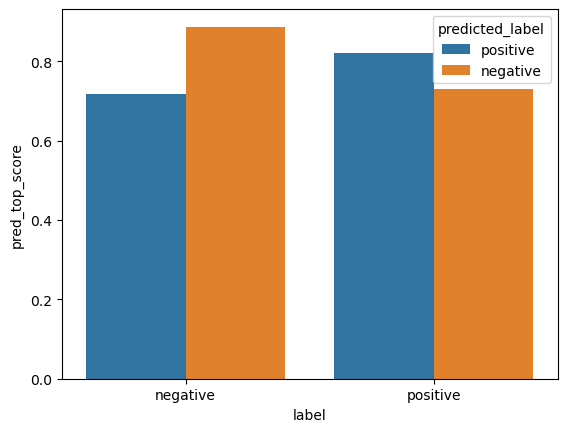

In [11]:
sns.barplot(
    data=pd.concat(
    [
        df_missclasified, 
        df_not_missclasified
    ]).reset_index(name="pred_top_score"), 
    x="label", y="pred_top_score", hue="predicted_label")
plt.show()

when it predicts wrongly, the confidence is lower

### now why is that? longer texts, double negation?

i have two ideas: text length and looking for double negations, so a dict of negation words and then count if they appear multiple times, additionally typicaly finance language like downgrade/upgrade

### text length

In [12]:
wordcount = df_preds["text"].str.split().str.len()
print(wordcount.value_counts().sort_index())

text
1      28
2      14
3      37
4     123
5     326
6     363
7     502
8     745
9     882
10    920
11    858
12    807
13    649
14    561
15    435
16    418
17    360
18    374
19    315
20    289
21    228
22    147
23     85
24     42
25     18
26     10
27      2
28      1
29      3
32      1
Name: count, dtype: int64


In [13]:
##above 25 small number of tweets, hence we can drop
df_below25 = df_preds[wordcount<25]
wordcounts_below25 = df_below25["text"].str.split().str.len()
error = (df_preds["label"] != df_preds["predicted_label"]).astype(int)
error = error[wordcount<25].astype(int)

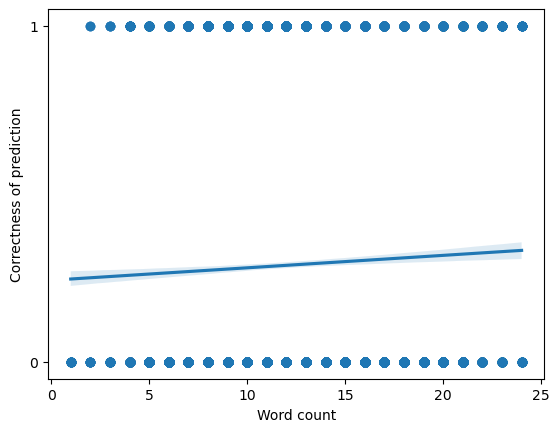

Corr coeff: 0.037609116509216244


In [14]:
sns.regplot(x=wordcounts_below25, y=error)
plt.xlabel("Word count")
plt.yticks([0,1])
plt.ylabel("Correctness of prediction")
plt.show()

print("Corr coeff:", wordcounts_below25.corr(error))

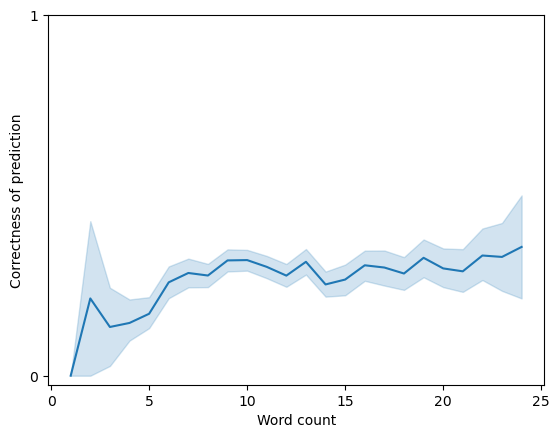

In [15]:
sns.lineplot(x=wordcounts_below25, y=error)
plt.xlabel("Word count")
plt.yticks([0,1])
plt.ylabel("Correctness of prediction")
plt.show()

In [16]:
### but we already lowkey knew that beforehand bcs neutral tweets are good

In [17]:
df_no_neutral = df_preds[df_preds["label"] != "neutral"].copy()

In [18]:
df_below25 = df_no_neutral[df_no_neutral["text"].str.split().str.len()<25]
wordcount = df_below25["text"].str.split().str.len()
error = (df_below25["label"] != df_below25["predicted_label"]).astype(int)

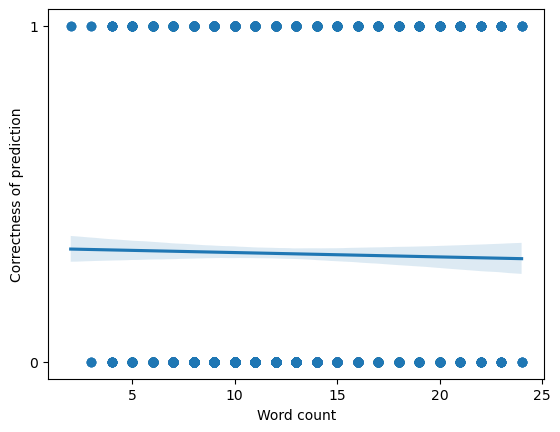

Corr coeff: -0.011790507154774942


In [19]:
sns.regplot(x=wordcount, y=error)
plt.xlabel("Word count")
plt.yticks([0,1])
plt.ylabel("Correctness of prediction")
plt.show()

print("Corr coeff:", wordcount.corr(error))

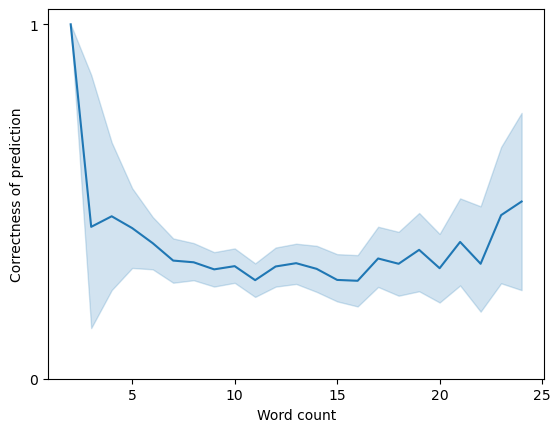

In [20]:
sns.lineplot(x=wordcount, y=error)
plt.xlabel("Word count")
plt.yticks([0,1])
plt.ylabel("Correctness of prediction")
plt.show()

### low corr for all tweets, neg corr for bullish/bearish tweets -> tweet length no impact on mistakes

### Double negation 

In [21]:
df_bear_but_pred_bull = df_no_neutral[
    (df_no_neutral["label"] == "negative")
    & (df_no_neutral["predicted_label"] == "positive")
    ]

df_bear_but_pred_neutral= df_no_neutral[
    (df_no_neutral["label"] == "negative")
    & (df_no_neutral["predicted_label"] == "neutral")
    ]

df_bear_and_pred_bear= df_no_neutral[
    (df_no_neutral["label"] == "negative")
    & (df_no_neutral["predicted_label"] == "negative")
    ]

In [22]:
bullish_words = {
    "gains", "gain", "overweight", "outperform", 
    "earnings", "growth", "soars", "climb", 
    "rose", "profits", "boom", "booming",
    "higher", "inched", "grow", "grows", 
    "grew", "gained", "record", "buys",
    "buy", "bought", "beats"
    

}

In [23]:
'''for word in bullish_words:
    matches_bull = df_bear_but_pred_bull["text"].str.contains(
        rf"\b{word}\b", case=False, na=False
    ).astype(int).mean() #proportion of tweets containing 1 word 
    matches_base = df_bear_but_pred_neutral["text"].str.contains(
        rf"\b{word}\b", case=False, na=False
    ).astype(int).mean() #proportion of tweets containing 1 word 
    matches_bear = df_bear_and_pred_bear["text"].str.contains(
        rf"\b{word}\b", case=False, na=False
    ).astype(int).mean() 
'''   
#proportion of tweets containing 1 word 
matches_bull = df_bear_but_pred_bull["text"].str.contains(r"\b(?:" + "|".join(bullish_words)+r")\b", case=False, na=False).mean()
matches_base = df_bear_but_pred_neutral["text"].str.contains(r"\b(?:" + "|".join(bullish_words)+r")\b", case=False, na=False).mean() 
matches_bear = df_bear_and_pred_bear["text"].str.contains(r"\b(?:" + "|".join(bullish_words)+r")\b", case=False, na=False).mean() 

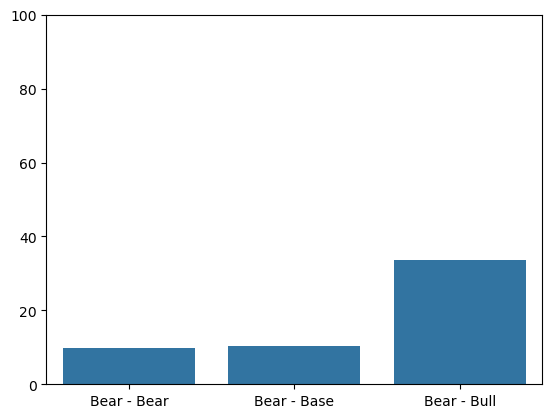

In [24]:
sns.barplot(
    x = ["Bear - Bear", "Bear - Base", "Bear - Bull",],
    y = [matches_bear*100, matches_base*100, matches_bull*100]
)
plt.ylim(0,100)
plt.show()

### I think this somewhat justifies my idea, but that also means 60 percent do not contain these words

## Scaled by score

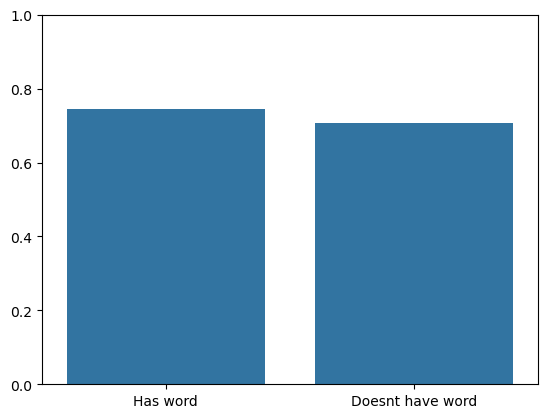

In [25]:
has_word = df_bear_but_pred_bull["text"].str.contains(r"\b(?:" + "|".join(bullish_words)+r")\b", case=False, na=False)
doesnt = ~has_word

sns.barplot(
    x = ["Has word", "Doesnt have word"],
    y = [
        df_bear_but_pred_bull.loc[has_word, "pred_top_score"].mean(), 
        df_bear_but_pred_bull.loc[doesnt, "pred_top_score"].mean()
    ]
)
plt.ylim(0,1)
plt.show()

### barely any difference

### the main problem with my analysis is that (and maybe the AI guys can make this better) that my list doesnt differentiate clearly between different types of financial statements -> e.g soars or climb are not necessarily bullish

### also we could investigate how numbres, rating changes, and mixed sentiment -> question is how do we analyse that visually. i guess here AI guys will have major advantages plus the same can be done for the reverse, actually bullish but predicted bearish